# Decoding the Rhythms of Emotion: A Sentimental Journey Through Music Genres
## Notebook 3 of 5 — Genre Identification

**Text Mining 2026/2027 | Group 15**

Raya Daher Alkhatib (20241416), Danyial Ahmad (20241831), Shaahir Racharla (20241419), Pedro Ambar (20231709)

| Notebook | Content |
|---|---|
| `01_eda` | Abstract, Introduction and Data Exploration |
| `02_preprocessing` | Initial Data Preprocessing |
| **`03_genre_classification`** | **Genre Identification** |
| `04_sentiment_analysis` | Sentiment Analysis |
| `05_conclusion_annexes` | Conclusion, References and Annexes |

**Run order:** `01 → 02 → 03 → 04 → 05`

Notebook 2 produces the cleaned datasets used in this notebook. Raw data are stored in `data/raw/`, while the processed datasets are stored in `data/processed/`.

The modelling decisions in this notebook build on the preprocessing and exploratory findings from the previous notebooks.

## Objective

The objective of this notebook is to predict the musical genre of each song from its lyrics.

The task is formulated as a multiclass single-label text classification problem with six possible genres.

The modelling strategy follows four stages:

1. Establish a baseline and compare classical text classifiers.
2. Diagnose class imbalance and improve the strongest initial model.
3. Evaluate alternative word- and character-level representations.
4. Select and evaluate the strongest classical machine-learning configuration.

Macro F1 is used as the primary evaluation metric because all genres should contribute equally to model assessment despite the class imbalance.

**Report section:** III. Genre Identification — additional preprocessing, feature selection, modelling strategy, model assessment and performance evaluation.

| | |
|---|---|
| **Inputs** | `data/processed/train_clean.pkl`, `data/processed/test_clean.pkl` |
| **Outputs** | `submissions/Group15_VersionNN.csv`, `results/submission_log.csv`, `results/experiment_log.csv` |
| **Run order** | `01` → `02` → `03` → `04` → `05` |

### Setup and Imports

In [1]:
%run ./_setup.py

import time

import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import hstack

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.pipeline import Pipeline, FeatureUnion

from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer
)

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

Repo root: /home/claude/Music-Genre-Identification | seed: 42


## 1. Data preparation

The cleaned datasets produced in the preprocessing notebook are loaded for genre classification.

The `clean` column contains the full-song representation selected during preprocessing. This notebook focuses on additional feature extraction, feature selection and predictive modelling.

In [2]:
# Only the id, the cleaned lyrics and the genre are used in this notebook. Loading just these columns
# (and not the raw text, sections and metadata) saves about 0.6 GB of memory.
train = pd.read_pickle(
    config.PROCESSED_DIR / "train_clean.pkl"
)[["id", "clean", "tag"]]

test = pd.read_pickle(
    config.PROCESSED_DIR / "test_clean.pkl"
)[["id", "clean"]]

print("Train:", train.shape)
print("Test:", test.shape)

Train: (134789, 3)
Test: (33742, 2)


In [3]:
X = train["clean"]
y = train["tag"]

X_test = test["clean"]

print("Training documents:", len(X))
print("Test documents:", len(X_test))
print("Genres:", sorted(y.unique()))

Training documents: 134789
Test documents: 33742
Genres: ['country', 'misc', 'pop', 'rap', 'rb', 'rock']


### Train-validation split

A stratified 80/20 holdout split is created before fitting the text representations and classifiers.

Stratification preserves the relative distribution of the six genres in both subsets. The official Kaggle test set remains untouched during model development.

In [4]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=config.SEED,
    stratify=y
)

print("Training split:", X_train.shape[0])
print("Validation split:", X_val.shape[0])

Training split: 107831
Validation split: 26958


## 2. Additional preprocessing and feature representation

Three initial text representations are considered:

- Bag-of-Words with word unigrams.
- TF-IDF with word unigrams.
- TF-IDF with word unigrams and bigrams.

Rare features are removed using `min_df` to reduce dimensionality and computational cost.

Preliminary dimensionality experiments with word unigram/bigram TF-IDF produced approximately 1.26 million features with `min_df=2`, 473 thousand with `min_df=5`, and 253 thousand with `min_df=10`. Therefore, `min_df=10` was retained for the word unigram/bigram representation.

No additional standard scaling is applied to the sparse text matrices. TF-IDF uses its default L2 normalization.

In [5]:
# Preliminary feature-selection experiments performed during development.
# They are kept commented to document how min_df=10 was selected without
# recreating several very large sparse matrices during Run All.

# for min_df_value in [2, 5, 10]:
#     temp_vectorizer = TfidfVectorizer(
#         token_pattern=r"(?u)\b\w+\b",
#         ngram_range=(1, 2),
#         min_df=min_df_value
#     )
#
#     X_temp = temp_vectorizer.fit_transform(X_train)
#
#     print(
#         f"min_df={min_df_value}: "
#         f"{X_temp.shape[1]} features"
#     )
#
#     del X_temp
#     del temp_vectorizer

### BoW

In [6]:
bow_vectorizer = CountVectorizer(
    token_pattern=r"(?u)\b\w+\b",
    ngram_range=(1, 1),
    min_df=2
)

X_train_bow = bow_vectorizer.fit_transform(X_train)
X_val_bow = bow_vectorizer.transform(X_val)

print("Training BoW:", X_train_bow.shape)
print("Validation BoW:", X_val_bow.shape)

Training BoW: (107831, 85481)
Validation BoW: (26958, 85481)


### TF-IDF unigram

In [7]:
tfidf_vectorizer = TfidfVectorizer(
    token_pattern=r"(?u)\b\w+\b",
    ngram_range=(1, 1),
    min_df=2
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_val_tfidf = tfidf_vectorizer.transform(X_val)

print("Training TF-IDF:", X_train_tfidf.shape)
print("Validation TF-IDF:", X_val_tfidf.shape)

Training TF-IDF: (107831, 85481)
Validation TF-IDF: (26958, 85481)


### TF-IDF word unigrams + bigrams

In [8]:
tfidf_bigram_vectorizer = TfidfVectorizer(
    token_pattern=r"(?u)\b\w+\b",
    ngram_range=(1, 2),
    min_df=10
)

X_train_tfidf_bigram = tfidf_bigram_vectorizer.fit_transform(
    X_train
)

X_val_tfidf_bigram = tfidf_bigram_vectorizer.transform(
    X_val
)

print(
    "Training TF-IDF (1,2):",
    X_train_tfidf_bigram.shape
)

print(
    "Validation TF-IDF (1,2):",
    X_val_tfidf_bigram.shape
)

Training TF-IDF (1,2): (107831, 252979)
Validation TF-IDF (1,2): (26958, 252979)


## 3. Initial model screening

A Dummy Classifier is first established as a baseline.

Three classical text classification algorithms are then compared:

- Logistic Regression
- Linear Support Vector Machine
- Multinomial Naive Bayes

The same holdout split is used throughout the comparison. Accuracy and Macro F1 are reported, with Macro F1 used as the primary criterion for model selection.

### Dummy Model

In [9]:
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

dummy_model.fit(
    X_train,
    y_train
)

y_val_pred_dummy = dummy_model.predict(X_val)

dummy_accuracy = accuracy_score(
    y_val,
    y_val_pred_dummy
)

dummy_macro_f1 = f1_score(
    y_val,
    y_val_pred_dummy,
    average="macro"
)

print("Dummy Classifier")
print(f"Accuracy: {dummy_accuracy:.4f}")
print(f"Macro F1: {dummy_macro_f1:.4f}")

Dummy Classifier
Accuracy: 0.4125
Macro F1: 0.0973


### Logistic Regression + TF-IDF unigram

In [10]:
logreg_tfidf = LogisticRegression(
    solver="saga",
    max_iter=1000,
    random_state=config.SEED
)

logreg_tfidf.fit(
    X_train_tfidf,
    y_train
)

y_val_pred_logreg_tfidf = logreg_tfidf.predict(
    X_val_tfidf
)

logreg_tfidf_accuracy = accuracy_score(
    y_val,
    y_val_pred_logreg_tfidf
)

logreg_tfidf_macro_f1 = f1_score(
    y_val,
    y_val_pred_logreg_tfidf,
    average="macro"
)

print("Logistic Regression + TF-IDF (1,1)")
print(f"Accuracy: {logreg_tfidf_accuracy:.4f}")
print(f"Macro F1: {logreg_tfidf_macro_f1:.4f}")

Logistic Regression + TF-IDF (1,1)
Accuracy: 0.6708
Macro F1: 0.4663


### Logistic Regression + TF-IDF bigram

In [11]:
logreg_tfidf_bigram = LogisticRegression(
    solver="saga",
    max_iter=1000,
    random_state=config.SEED
)

logreg_tfidf_bigram.fit(
    X_train_tfidf_bigram,
    y_train
)

y_val_pred_logreg_tfidf_bigram = logreg_tfidf_bigram.predict(
    X_val_tfidf_bigram
)

logreg_tfidf_bigram_accuracy = accuracy_score(
    y_val,
    y_val_pred_logreg_tfidf_bigram
)

logreg_tfidf_bigram_macro_f1 = f1_score(
    y_val,
    y_val_pred_logreg_tfidf_bigram,
    average="macro"
)

print("Logistic Regression + TF-IDF (1,2)")
print(f"Accuracy: {logreg_tfidf_bigram_accuracy:.4f}")
print(f"Macro F1: {logreg_tfidf_bigram_macro_f1:.4f}")

Logistic Regression + TF-IDF (1,2)
Accuracy: 0.6720
Macro F1: 0.4569


### Linear SVM unigram

In [12]:
linear_svm_tfidf = LinearSVC(
    C=1.0,
    random_state=config.SEED
)

linear_svm_tfidf.fit(
    X_train_tfidf,
    y_train
)

y_val_pred_svm_tfidf = linear_svm_tfidf.predict(
    X_val_tfidf
)

svm_tfidf_accuracy = accuracy_score(
    y_val,
    y_val_pred_svm_tfidf
)

svm_tfidf_macro_f1 = f1_score(
    y_val,
    y_val_pred_svm_tfidf,
    average="macro"
)

print("Linear SVM + TF-IDF (1,1)")
print(f"Accuracy: {svm_tfidf_accuracy:.4f}")
print(f"Macro F1: {svm_tfidf_macro_f1:.4f}")

Linear SVM + TF-IDF (1,1)
Accuracy: 0.6588
Macro F1: 0.4604


### SVM word bigrams

In [13]:
linear_svm_tfidf_bigram = LinearSVC(
    C=1.0,
    random_state=config.SEED
)

linear_svm_tfidf_bigram.fit(
    X_train_tfidf_bigram,
    y_train
)

y_val_pred_svm_tfidf_bigram = linear_svm_tfidf_bigram.predict(
    X_val_tfidf_bigram
)

svm_tfidf_bigram_accuracy = accuracy_score(
    y_val,
    y_val_pred_svm_tfidf_bigram
)

svm_tfidf_bigram_macro_f1 = f1_score(
    y_val,
    y_val_pred_svm_tfidf_bigram,
    average="macro"
)

print("Linear SVM + TF-IDF (1,2)")
print(f"Accuracy: {svm_tfidf_bigram_accuracy:.4f}")
print(f"Macro F1: {svm_tfidf_bigram_macro_f1:.4f}")

Linear SVM + TF-IDF (1,2)
Accuracy: 0.6561
Macro F1: 0.4789


### Naive Bayes + BoW

In [14]:
nb_bow = MultinomialNB(
    alpha=1.0  # Laplace smoothing to avoid zero probabilities
)

nb_bow.fit(
    X_train_bow,
    y_train
)

y_val_pred_nb_bow = nb_bow.predict(
    X_val_bow
)

nb_bow_accuracy = accuracy_score(
    y_val,
    y_val_pred_nb_bow
)

nb_bow_macro_f1 = f1_score(
    y_val,
    y_val_pred_nb_bow,
    average="macro"
)

print("Multinomial Naive Bayes + Bag-of-Words")
print(f"Accuracy: {nb_bow_accuracy:.4f}")
print(f"Macro F1: {nb_bow_macro_f1:.4f}")

Multinomial Naive Bayes + Bag-of-Words
Accuracy: 0.5632
Macro F1: 0.4694


### Naive Bayes + TF-IDF

In [15]:
nb_tfidf = MultinomialNB(
    alpha=1.0  # Laplace smoothing to avoid zero probabilities
)

nb_tfidf.fit(
    X_train_tfidf,
    y_train
)

y_val_pred_nb_tfidf = nb_tfidf.predict(
    X_val_tfidf
)

nb_tfidf_accuracy = accuracy_score(
    y_val,
    y_val_pred_nb_tfidf
)

nb_tfidf_macro_f1 = f1_score(
    y_val,
    y_val_pred_nb_tfidf,
    average="macro"
)

print("Multinomial Naive Bayes + TF-IDF")
print(f"Accuracy: {nb_tfidf_accuracy:.4f}")
print(f"Macro F1: {nb_tfidf_macro_f1:.4f}")

Multinomial Naive Bayes + TF-IDF
Accuracy: 0.6188
Macro F1: 0.2928


### Initial Comparison

In [16]:
initial_results = pd.DataFrame({
    "Model": [
        "Dummy Classifier",
        "Logistic Regression + TF-IDF (1,1)",
        "Logistic Regression + TF-IDF (1,2)",
        "Linear SVM + TF-IDF (1,1)",
        "Linear SVM + TF-IDF (1,2)",
        "Multinomial NB + BoW",
        "Multinomial NB + TF-IDF"
    ],
    "Accuracy": [
        dummy_accuracy,
        logreg_tfidf_accuracy,
        logreg_tfidf_bigram_accuracy,
        svm_tfidf_accuracy,
        svm_tfidf_bigram_accuracy,
        nb_bow_accuracy,
        nb_tfidf_accuracy
    ],
    "Macro F1": [
        dummy_macro_f1,
        logreg_tfidf_macro_f1,
        logreg_tfidf_bigram_macro_f1,
        svm_tfidf_macro_f1,
        svm_tfidf_bigram_macro_f1,
        nb_bow_macro_f1,
        nb_tfidf_macro_f1
    ]
})

initial_results.sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Macro F1
0,"Linear SVM + TF-IDF (1,2)",0.656058,0.478894
1,Multinomial NB + BoW,0.563172,0.469392
2,"Logistic Regression + TF-IDF (1,1)",0.670821,0.466294
3,"Linear SVM + TF-IDF (1,1)",0.658803,0.460386
4,"Logistic Regression + TF-IDF (1,2)",0.672008,0.456876
5,Multinomial NB + TF-IDF,0.618814,0.292828
6,Dummy Classifier,0.412494,0.097344


The initial screening shows that no single text representation performs best across all classifiers.

Linear SVM with word unigram and bigram TF-IDF achieves the highest initial Macro F1 (0.4789), while Multinomial Naive Bayes performs competitively with Bag-of-Words (0.4694).

The difference between accuracy and Macro F1 across several configurations also indicates uneven performance between genres. Linear SVM with unigram and bigram TF-IDF is therefore selected for further diagnosis and improvement.

## 4. Improving the strongest initial model

### Class-level diagnosis

The strongest initial model is evaluated at the class level to determine whether its overall performance hides substantial differences between genres.

In [17]:
print(
    classification_report(
        y_val,
        y_val_pred_svm_tfidf_bigram,
        labels=config.LABELS,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

     country     0.4667    0.1212    0.1924       693
        misc     0.8051    0.4813    0.6024      1124
         pop     0.6122    0.7614    0.6787     11120
         rap     0.8453    0.8655    0.8553      7716
          rb     0.3867    0.0935    0.1506      1240
        rock     0.4416    0.3554    0.3938      5065

    accuracy                         0.6561     26958
   macro avg     0.5929    0.4464    0.4789     26958
weighted avg     0.6408    0.6561    0.6358     26958



The class-level evaluation reveals substantial performance differences across genres.

Rap is classified particularly well, while country and rb obtain very low recall values. The results indicate that the overall score is influenced by the more frequent genres and motivate explicitly addressing class imbalance.

### Addressing class imbalance

The same model is retrained with `class_weight="balanced"`. Each genre then gets the same total weight during training, so a mistake on a country or rb song costs the model more than a mistake on a pop song.

In [18]:
linear_svm_balanced = LinearSVC(
    C=1.0,
    class_weight="balanced",
    random_state=config.SEED
)

linear_svm_balanced.fit(
    X_train_tfidf_bigram,
    y_train
)

y_val_pred_svm_balanced = linear_svm_balanced.predict(
    X_val_tfidf_bigram
)

svm_balanced_accuracy = accuracy_score(
    y_val,
    y_val_pred_svm_balanced
)

svm_balanced_macro_f1 = f1_score(
    y_val,
    y_val_pred_svm_balanced,
    average="macro"
)

print("Balanced Linear SVM + TF-IDF (1,2)")
print(f"Accuracy: {svm_balanced_accuracy:.4f}")
print(f"Macro F1: {svm_balanced_macro_f1:.4f}")

Balanced Linear SVM + TF-IDF (1,2)
Accuracy: 0.6387
Macro F1: 0.5101


Balanced class weights increase Macro F1 from 0.4789 to 0.5101.

The improvement is particularly visible in the minority genres, while performance on the dominant genres remains comparatively strong. Balanced class weighting is therefore retained for the subsequent Linear SVM experiments.

## 5. Word-level model tuning

The regularization parameter `C` of the balanced Linear SVM is tuned using 5-fold stratified cross-validation.

Macro F1 is used as the optimization criterion. The held-out validation set is not used for hyperparameter selection.

In [19]:

# NOTE: This Grid Search was run during model development to select the
# regularization parameter. It is commented out in the final notebook to avoid
# repeating a computationally expensive search during Run All.
# The selected parameter is used explicitly in the active model below.

# svm_pipeline = Pipeline([
#     (
#         "tfidf",
#         TfidfVectorizer(
#             token_pattern=r"(?u)\b\w+\b",
#             ngram_range=(1, 2),
#             min_df=10
#         )
#     ),
#     (
#         "svm",
#         LinearSVC(
#             class_weight="balanced",
#             random_state=config.SEED
#         )
#     )
# ])
#
# cv = StratifiedKFold(
#     n_splits=5,
#     shuffle=True,
#     random_state=config.SEED
# )
#
# param_grid = {
#     "svm__C": [0.25, 0.5, 1.0, 2.0, 4.0]
# }
#
# grid_search = GridSearchCV(
#     estimator=svm_pipeline,
#     param_grid=param_grid,
#     scoring="f1_macro",
#     cv=cv,
#     n_jobs=1,
#     verbose=2
# )
#
# grid_search.fit(X_train, y_train)
#
# print("Best C:", grid_search.best_params_["svm__C"])
# print(f"Best mean CV Macro F1: {grid_search.best_score_:.4f}")

The Grid Search selected:

- **C = 0.25**
- **Mean 5-fold CV Macro F1 = 0.5266**

The selected value is used explicitly in the active model below.

### Tuned word model

In [20]:
linear_svm_tuned = LinearSVC(
    C=0.25,
    class_weight="balanced",
    random_state=config.SEED
)

linear_svm_tuned.fit(
    X_train_tfidf_bigram,
    y_train
)

y_val_pred_svm_tuned = linear_svm_tuned.predict(
    X_val_tfidf_bigram
)

svm_tuned_accuracy = accuracy_score(
    y_val,
    y_val_pred_svm_tuned
)

svm_tuned_macro_f1 = f1_score(
    y_val,
    y_val_pred_svm_tuned,
    average="macro"
)

print("Tuned Word-Level Linear SVM")
print(f"Accuracy: {svm_tuned_accuracy:.4f}")
print(f"Macro F1: {svm_tuned_macro_f1:.4f}")

Tuned Word-Level Linear SVM
Accuracy: 0.6524
Macro F1: 0.5321


Reducing `C` from 1.0 to 0.25 improves both evaluation metrics. Macro F1 increases from 0.5101 to 0.5321, while accuracy increases from 0.6387 to 0.6524.

The tuned word-level configuration becomes the strongest model at this stage.

### Two preprocessing choices, checked on this model

Notebook 2 made two choices that we wanted to confirm with numbers rather than argue for: keeping stopwords, and turning
section tags such as `[Hook]` into tokens (`sec_hook`). We retrained the tuned word model twice on the same split,
changing one thing each time:

- **stopwords removed**: the NLTK English stopword list (the one used in the practical classes) is dropped inside the vectorizer;
- **section tokens removed**: every `sec_...` token is deleted from the text before vectorising.

In [21]:
# CHECKED AND NOT ADOPTED: both variants scored below the tuned word model (results in the markdown below),
# so notebook 2 keeps stopwords and section tokens. Commented out because it refits two 250k-feature models.
#
# import nltk
# nltk.download("stopwords", quiet=True)
# from nltk.corpus import stopwords
#
# variants = {
#     "stopwords removed": (X_train, X_val, stopwords.words("english")),
#     "section tokens removed": (X_train.str.replace(r"\bsec_\w+", " ", regex=True),
#                                X_val.str.replace(r"\bsec_\w+", " ", regex=True), None),
# }
# for name, (train_text, val_text, stop_list) in variants.items():
#     vectorizer = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b", ngram_range=(1, 2), min_df=10, stop_words=stop_list)
#     model = LinearSVC(C=0.25, class_weight="balanced", random_state=config.SEED)
#     model.fit(vectorizer.fit_transform(train_text), y_train)
#     pred = model.predict(vectorizer.transform(val_text))
#     print(f"{name}: accuracy {accuracy_score(y_val, pred):.4f} | macro F1 {f1_score(y_val, pred, average='macro'):.4f}")

**What we found** (holdout split, same settings as the tuned word model above):

| Variant | Accuracy | Macro F1 |
|---|---|---|
| Tuned word model (stopwords and section tokens kept) | 0.6524 | 0.5321 |
| Stopwords removed (NLTK English list) | 0.6437 | 0.5160 |
| Section tokens removed | 0.6347 | 0.5171 |

Both changes cost about 0.015 macro F1. Stopwords are not noise in lyrics: pronouns and short function words carry the
way a song addresses someone ("you", "we", "me"), which differs between genres. Section tokens carry structure: notebook 1
showed that the type of section depends on the genre (`[Hook]` is almost only used in rap, while pop uses
`[Pre-Chorus]` more). → Notebook 2's
choices stay: stopwords and section tokens are kept.

### Freeing memory before the character features

The bag-of-words and unigram TF-IDF matrices were only needed for the screening in Section 3. The character features
below are large (over 100,000 columns and around 1.5 GB), so we delete the old matrices first to keep the notebook within
the memory of an ordinary 8 GB laptop.

In [22]:
import gc

from src.features import hstack_csr

del X_train_bow, X_val_bow, X_train_tfidf, X_val_tfidf
gc.collect()

0

## 6. Character-level representation

Word-level TF-IDF captures lexical information, but lyrics also contain slang, contractions, spelling variations and stylistic word forms.

Character n-grams are therefore evaluated as an alternative representation capable of capturing subword patterns.

In [23]:
char_tfidf_vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=10,
    max_features=250000
)

X_train_char = char_tfidf_vectorizer.fit_transform(
    X_train
)

X_val_char = char_tfidf_vectorizer.transform(
    X_val
)

print("Training Character TF-IDF:", X_train_char.shape)
print("Validation Character TF-IDF:", X_val_char.shape)

Training Character TF-IDF: (107831, 112092)
Validation Character TF-IDF: (26958, 112092)


### Character Tuning

In [24]:
# NOTE: This Grid Search was run during model development to select the
# regularization parameter for the combined word + character representation.
# It is commented out in the final notebook because of its high computational
# cost. The selected parameter is used explicitly in the active model below.

# char_pipeline = Pipeline([
#     (
#         "tfidf",
#         TfidfVectorizer(
#             analyzer="char_wb",
#             ngram_range=(3, 5),
#             min_df=10,
#             max_features=250000
#         )
#     ),
#     (
#         "svm",
#         LinearSVC(
#             class_weight="balanced",
#             random_state=config.SEED
#         )
#     )
# ])
#
# char_cv = StratifiedKFold(
#     n_splits=3,
#     shuffle=True,
#     random_state=config.SEED
# )
#
# char_param_grid = {
#     "svm__C": [0.1, 0.25, 0.5, 1.0]
# }
#
# char_grid_search = GridSearchCV(
#     estimator=char_pipeline,
#     param_grid=char_param_grid,
#     scoring="f1_macro",
#     cv=char_cv,
#     n_jobs=1,
#     verbose=2
# )
#
# char_grid_search.fit(X_train, y_train)
#
# print("Best C:", char_grid_search.best_params_["svm__C"])
# print(f"Best mean CV Macro F1: {char_grid_search.best_score_:.4f}")

The character-level tuning selected:

- **C = 0.1**
- **Mean 3-fold CV Macro F1 = 0.5145**

The character representation remains competitive but performs below the tuned word-level representation.

### Tuned Character Model

In [25]:
linear_svm_char_tuned = LinearSVC(
    C=0.1,
    class_weight="balanced",
    random_state=config.SEED
)

linear_svm_char_tuned.fit(
    X_train_char,
    y_train
)

y_val_pred_svm_char_tuned = linear_svm_char_tuned.predict(
    X_val_char
)

svm_char_tuned_accuracy = accuracy_score(
    y_val,
    y_val_pred_svm_char_tuned
)

svm_char_tuned_macro_f1 = f1_score(
    y_val,
    y_val_pred_svm_char_tuned,
    average="macro"
)

print("Tuned Character-Level Linear SVM")
print(f"Accuracy: {svm_char_tuned_accuracy:.4f}")
print(f"Macro F1: {svm_char_tuned_macro_f1:.4f}")

Tuned Character-Level Linear SVM
Accuracy: 0.6339
Macro F1: 0.5203


The tuned character-level model achieves a Macro F1 of 0.5203.

Although it remains below the tuned word-level model (0.5321), its competitive performance suggests that character n-grams capture complementary stylistic information that may be useful when combined with word-level features.

## 7. Combined word and character representation

Word-level and character-level TF-IDF capture different information from song lyrics.

Word n-grams capture lexical and short contextual patterns, while character n-grams capture subword and stylistic patterns.

The two sparse representations are therefore combined to determine whether their complementary information improves genre classification.

In [26]:
# hstack_csr (src/features.py) gives the same matrix as scipy's hstack but needs far less memory while building it.
X_train_combined = hstack_csr(X_train_tfidf_bigram, X_train_char)
# The separate word and character matrices are not used again once combined. Deleting them right away keeps the
# peak memory low enough for an 8 GB laptop.
del X_train_tfidf_bigram, X_train_char

X_val_combined = hstack_csr(X_val_tfidf_bigram, X_val_char)
del X_val_tfidf_bigram, X_val_char
gc.collect()

print("Combined training shape:", X_train_combined.shape)
print("Combined validation shape:", X_val_combined.shape)


Combined training shape: (107831, 365071)
Combined validation shape: (26958, 365071)


### Combined Tuning — Grid Search

In [27]:
# NOTE: This Grid Search was run during model development to select the
# regularization parameter for the combined word + character representation.
# It is commented out in the final notebook because of its high computational
# cost. The selected parameter is used explicitly in the active model below.

# combined_pipeline = Pipeline([
#     (
#         "features",
#         FeatureUnion([
#             (
#                 "word",
#                 TfidfVectorizer(
#                     token_pattern=r"(?u)\b\w+\b",
#                     ngram_range=(1, 2),
#                     min_df=10
#                 )
#             ),
#             (
#                 "char",
#                 TfidfVectorizer(
#                     analyzer="char_wb",
#                     ngram_range=(3, 5),
#                     min_df=10,
#                     max_features=250000
#                 )
#             )
#         ])
#     ),
#     (
#         "svm",
#         LinearSVC(
#             class_weight="balanced",
#             random_state=config.SEED
#         )
#     )
# ])
#
# combined_cv = StratifiedKFold(
#     n_splits=3,
#     shuffle=True,
#     random_state=config.SEED
# )
#
# combined_param_grid = {
#     "svm__C": [0.1, 0.25, 0.5]
# }
#
# combined_grid_search = GridSearchCV(
#     estimator=combined_pipeline,
#     param_grid=combined_param_grid,
#     scoring="f1_macro",
#     cv=combined_cv,
#     n_jobs=1,
#     verbose=2
# )
#
# combined_grid_search.fit(X_train, y_train)
#
# print("Best C:", combined_grid_search.best_params_["svm__C"])
# print(f"Best mean CV Macro F1: {combined_grid_search.best_score_:.4f}")

The combined representation tuning selected:

- **C = 0.1**
- **Mean 3-fold CV Macro F1 = 0.5303**

The selected value is used in the active combined model below.

### Final combined Linear SVM

The selected combined representation is evaluated on the held-out validation set using the tuned regularization parameter and balanced class weights.

In [28]:
linear_svm_combined_tuned = LinearSVC(
    C=0.1,
    class_weight="balanced",
    random_state=config.SEED
)

linear_svm_combined_tuned.fit(
    X_train_combined,
    y_train
)

y_val_pred_svm_combined_tuned = (
    linear_svm_combined_tuned.predict(
        X_val_combined
    )
)

svm_combined_tuned_accuracy = accuracy_score(
    y_val,
    y_val_pred_svm_combined_tuned
)

svm_combined_tuned_macro_f1 = f1_score(
    y_val,
    y_val_pred_svm_combined_tuned,
    average="macro"
)

print("Tuned Word + Character Linear SVM")
print(f"Accuracy: {svm_combined_tuned_accuracy:.4f}")
print(f"Macro F1: {svm_combined_tuned_macro_f1:.4f}")

Tuned Word + Character Linear SVM
Accuracy: 0.6555
Macro F1: 0.5410


### Final 5-fold CV

In [29]:
# NOTE: This 5-fold cross-validation was run during model development to assess
# the stability of the final classical model. It is commented out in the final
# notebook because of its computational cost. Its results are reported in the
# accompanying Markdown, and no subsequent cell depends on these variables.


# combined_final_pipeline = Pipeline([
#     (
#         "features",
#         FeatureUnion([
#             (
#                 "word",
#                 TfidfVectorizer(
#                     token_pattern=r"(?u)\b\w+\b",
#                     ngram_range=(1, 2),
#                     min_df=10
#                 )
#             ),
#             (
#                 "char",
#                 TfidfVectorizer(
#                     analyzer="char_wb",
#                     ngram_range=(3, 5),
#                     min_df=10,
#                     max_features=250000
#                 )
#             )
#         ])
#     ),
#     (
#         "svm",
#         LinearSVC(
#             C=0.1,
#             class_weight="balanced",
#             random_state=config.SEED
#         )
#     )
# ])
#
# combined_cv_5 = StratifiedKFold(
#     n_splits=5,
#     shuffle=True,
#     random_state=config.SEED
# )
#
# combined_cv_results = cross_validate(
#     combined_final_pipeline,
#     X_train,
#     y_train,
#     cv=combined_cv_5,
#     scoring={
#         "accuracy": "accuracy",
#         "macro_f1": "f1_macro"
#     },
#     n_jobs=1
# )
#
# print("Macro F1 per fold:", combined_cv_results["test_macro_f1"])
# print(f"Mean Macro F1: {combined_cv_results['test_macro_f1'].mean():.4f}")
# print(f"Std Macro F1: {combined_cv_results['test_macro_f1'].std():.4f}")
# print()
# print("Accuracy per fold:", combined_cv_results["test_accuracy"])
# print(f"Mean Accuracy: {combined_cv_results['test_accuracy'].mean():.4f}")

### Cross-validation stability

The final combined configuration was also evaluated using 5-fold stratified cross-validation.

Results:

- **Mean Macro F1 = 0.5342**
- **Standard deviation = 0.0039**
- **Mean Accuracy = 0.6498**

The low variation between folds indicates that the model performs consistently across different training subsets. The cross-validation result is also consistent with the holdout Macro F1 of 0.5410.

## 8. Model development summary

In [30]:
model_progression = pd.DataFrame({
    "Configuration": [
        "Initial Word SVM",
        "Balanced Word SVM",
        "Tuned Word SVM",
        "Tuned Character SVM",
        "Tuned Word + Character SVM"
    ],
    "Accuracy": [
        svm_tfidf_bigram_accuracy,
        svm_balanced_accuracy,
        svm_tuned_accuracy,
        svm_char_tuned_accuracy,
        svm_combined_tuned_accuracy
    ],
    "Macro F1": [
        svm_tfidf_bigram_macro_f1,
        svm_balanced_macro_f1,
        svm_tuned_macro_f1,
        svm_char_tuned_macro_f1,
        svm_combined_tuned_macro_f1
    ]
})

model_progression

,Configuration,Accuracy,Macro F1
0,Initial Word SVM,0.656058,0.478894
1,Balanced Word SVM,0.638697,0.510074
2,Tuned Word SVM,0.652422,0.532053
3,Tuned Character SVM,0.633875,0.520299
4,Tuned Word + Character SVM,0.655501,0.541045


## 9. Final classical model evaluation

### Class-level performance

The strongest classical model is evaluated across all six genres using precision, recall and F1-score.

In [31]:
print(
    classification_report(
        y_val,
        y_val_pred_svm_combined_tuned,
        labels=config.LABELS,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

     country     0.2886    0.4315    0.3459       693
        misc     0.5899    0.6246    0.6067      1124
         pop     0.6695    0.6570    0.6632     11120
         rap     0.8657    0.8681    0.8669      7716
          rb     0.2686    0.3258    0.2945      1240
        rock     0.4940    0.4466    0.4691      5065

    accuracy                         0.6555     26958
   macro avg     0.5294    0.5589    0.5410     26958
weighted avg     0.6612    0.6555    0.6576     26958



The final model performs particularly well for rap, while country and rb remain the most difficult genres to identify.

The direct class-level comparison shows that the combined representation improves F1-score for country, pop, rap, rb and rock, while misc experiences a small decrease.

The largest gains among the more difficult genres are observed for country, rb and rock. This suggests that character-level information provides useful complementary information beyond word-level TF-IDF.

Overall, Macro F1 increases from 0.5321 for the tuned word-only model to 0.5410 for the combined representation.

In [32]:
word_class_report = classification_report(
    y_val,
    y_val_pred_svm_tuned,
    labels=config.LABELS,
    output_dict=True,
    zero_division=0
)

combined_class_report = classification_report(
    y_val,
    y_val_pred_svm_combined_tuned,
    labels=config.LABELS,
    output_dict=True,
    zero_division=0
)

class_f1_comparison = pd.DataFrame({
    "Word-only F1": [
        word_class_report[label]["f1-score"]
        for label in config.LABELS
    ],
    "Word + Character F1": [
        combined_class_report[label]["f1-score"]
        for label in config.LABELS
    ]
}, index=config.LABELS)

class_f1_comparison["Difference"] = (
    class_f1_comparison["Word + Character F1"]
    - class_f1_comparison["Word-only F1"]
)

class_f1_comparison.index.name = "Genre"

class_f1_comparison.round(4)

,Word-only F1,Word + Character F1,Difference
Genre,,,
country,0.3278,0.3459,0.0181
misc,0.6133,0.6067,-0.0066
pop,0.6612,0.6632,0.0020
rap,0.8638,0.8669,0.0031
rb,0.2700,0.2945,0.0244
rock,0.4563,0.4691,0.0128


### Confusion matrix

A normalized confusion matrix is used to examine the remaining error patterns of the strongest classical model.

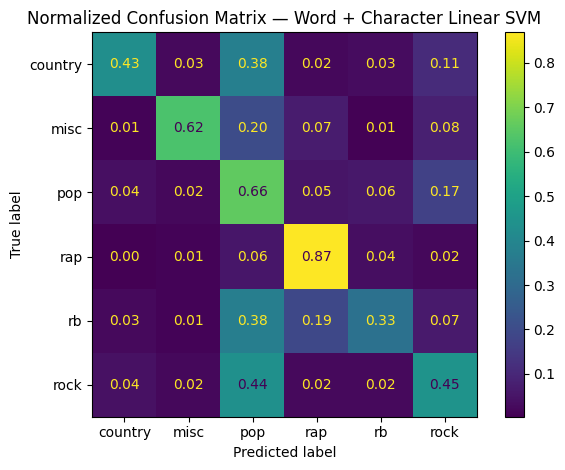

In [33]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_svm_combined_tuned,
    labels=config.LABELS,
    normalize="true",
    values_format=".2f"
)

plt.title(
    "Normalized Confusion Matrix — "
    "Word + Character Linear SVM"
)

plt.tight_layout()
plt.show()

Rap is the most clearly distinguishable genre, with approximately 87% of songs correctly classified.

Pop remains the main destination for several classification errors. Country, rb and rock are frequently predicted as pop, indicating substantial overlap between the textual patterns associated with these genres.

These remaining confusion patterns help explain why country, rb and rock continue to obtain lower class-level F1-scores than rap and pop.

## 10. Classical modelling conclusion

Among the initial classifiers, Linear SVM with word unigram and bigram TF-IDF provided the strongest starting point.

Class weighting substantially improved performance on underrepresented genres, while hyperparameter tuning further increased Macro F1.

Character-level TF-IDF was competitive but weaker as a standalone representation. However, combining word- and character-level features produced the strongest classical configuration.

The final classical model uses:

- word TF-IDF with unigrams and bigrams;
- character TF-IDF with 3–5 character n-grams;
- balanced Linear SVM;
- `C = 0.1`.

It achieves a holdout Macro F1 of **0.5410** and a 5-fold cross-validation Macro F1 of **0.5342 ± 0.0039**.

This is our final genre classifier. Section 11 refits it on all training songs and writes the Kaggle submission.

## 11. Final model and Kaggle submission

The model we submit is the one evaluated in Section 7: word + character TF-IDF with a balanced Linear SVM (`C = 0.1`),
trained on the 80% training split. We only have to turn the test lyrics into the same features, using the vectorizers
already fitted on the training split, and predict. Nothing is fitted on the test set, so no test information leaks in.

**What we tried first and why it is commented out.** The usual last step is to refit the chosen configuration on *all*
134,789 training songs, so the rare genres get about 25% more examples. We tried it, but after building the character
vocabulary on every song the process already used 5.2 GB of memory, and it was killed in the next step on our 6 GB test
machine. A notebook that crashes on the graders' laptops costs far more than
the small gain from 20% more data, so we kept the refit as a commented cell and submit the model whose holdout and
cross-validation scores we actually measured.

In [34]:
# TRIED AND NOT KEPT: refit on all training songs. Commented out because it needs more memory than an 8 GB laptop has
# (memory reached 5.2 GB after the character vectorizer on all training songs, then the process was killed).
#
# final_word_vectorizer = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b", ngram_range=(1, 2), min_df=10)
# final_char_vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=10, max_features=250000)
# X_full = hstack([final_word_vectorizer.fit_transform(X), final_char_vectorizer.fit_transform(X)], format="csr")
# final_model = LinearSVC(C=0.1, class_weight="balanced", random_state=config.SEED).fit(X_full, y)
# X_test_full = hstack([final_word_vectorizer.transform(X_test), final_char_vectorizer.transform(X_test)], format="csr")
# test_predictions = final_model.predict(X_test_full)

In [35]:
# The training and validation matrices are not needed any more; freeing them keeps memory low.
del X_train_combined, X_val_combined
gc.collect()

start = time.time()
X_test_combined = hstack_csr(tfidf_bigram_vectorizer.transform(X_test), char_tfidf_vectorizer.transform(X_test))
test_predictions = linear_svm_combined_tuned.predict(X_test_combined)

print("Test matrix:", X_test_combined.shape)
print(f"Feature extraction and prediction time: {time.time() - start:.0f} s")

Test matrix: (33742, 365071)
Feature extraction and prediction time: 63 s


**A sanity check before uploading.** We have no labels for the test set, but we can compare how often each genre is
predicted with how often it appears in training and how often the same model predicted it on the validation split.
A model that suddenly predicted 70% pop, or almost no rap, would point to a bug in the pipeline (for example the test text
not being cleaned the same way).

In [36]:
prediction_check = pd.DataFrame({
    "share in training": y.value_counts(normalize=True),
    "share of validation predictions (Section 7)": pd.Series(y_val_pred_svm_combined_tuned).value_counts(normalize=True),
    "share of test predictions": pd.Series(test_predictions).value_counts(normalize=True),
}).loc[config.LABELS]
prediction_check.round(3)

,share in training,share of validation predictions (Section 7),share of test predictions
country,0.026,0.038,0.038
misc,0.042,0.044,0.046
pop,0.413,0.405,0.403
rap,0.286,0.287,0.290
rb,0.046,0.056,0.054
rock,0.188,0.170,0.170


**What we see.** The test predictions have almost exactly the same genre shares as the validation predictions of the same
model (for example 40.3% vs 40.5% pop, 29.0% vs 28.7% rap, 3.8% vs 3.8% country). Both predict the rare genres a bit
more often than they occur in training (country 3.8% vs 2.6%, rb 5.4% vs 4.6%) and rock a bit less (17.0% vs 18.8%).
That is the expected effect of the balanced class weights, which make the model more willing to choose a small genre.

**What it means.** The test set went through the same pipeline as the validation set and nothing looks broken, so the
file can be written.

### Writing and logging the submission file

`write_submission` (in `src/submission.py`) refuses to write the file unless it has exactly one prediction for every id in
Kaggle's `sample_submission.csv` and only uses the six known genres. The file's SHA-256 hash is a fingerprint of its
exact bytes: if the hash in `results/submission_log.csv` matches the file selected on Kaggle, the submission is exactly
what this notebook produces.

In [37]:
from src.evaluation import log_experiment
from src.submission import file_sha256, log_submission, write_submission

SUBMISSION_VERSION = 2
CV_MACRO_F1, CV_MACRO_F1_STD = 0.5342, 0.0039      # 5-fold CV of this configuration (Section 7, commented cell)

submission_path = write_submission(test["id"], test_predictions, version=SUBMISSION_VERSION)
print("Written:", submission_path.name)
print("SHA-256:", file_sha256(submission_path))

log_submission(submission_path, CV_MACRO_F1, exp_id="03_final",
               notes="word (1,2) + char_wb (3,5) TF-IDF, balanced LinearSVC C=0.1, trained on the 80% split")
log_experiment(
    "03_final",
    notebook="03_genre_classification",
    cleaning_config="notebook 02 clean column (lowercase, section tokens, stopwords kept)",
    representation="TF-IDF word 1-2 (min_df=10) + char_wb 3-5 (min_df=10, max 250k)",
    model="LinearSVC class_weight=balanced",
    params="C=0.1",
    cv_macro_f1_mean=CV_MACRO_F1,
    cv_macro_f1_std=CV_MACRO_F1_STD,
    notes=f"holdout macro F1 {svm_combined_tuned_macro_f1:.4f}, accuracy {svm_combined_tuned_accuracy:.4f}",
)
pd.read_csv(config.SUBMISSION_LOG)

Written: Group15_Version02.csv
SHA-256: 469488a4113aac258beaf408e6f9b7e37a816b61ccafe3fc6ced9eec250f47e2


,version,file_name,date,exp_id,sha256,cv_macro_f1,public_lb_macro_f1,notes
0,2,Group15_Version02.csv,2026-11-04,03_final,469488a4113aac258beaf408e6f9b7e37a816b61ccafe3fc6ced9eec250f47e2,0.5342,NaN,"word (1,2) + char_wb (3,5) TF-IDF, balanced LinearSVC C=0.1, trained on the 80% split"


The submission file passed every check and its fingerprint is in `results/submission_log.csv`. The public leaderboard
score is added to that log by hand after uploading. To keep the Kaggle score and the notebook consistent, the final
submission selected on Kaggle must be the file with this hash, which re-running this notebook reproduces.

## Key takeaways → next notebook

- Lyrics alone carry a clear but limited genre signal: the final model reaches a macro F1 of **0.534 ± 0.004** in 5-fold
  cross-validation (0.541 on the holdout), against 0.097 for always predicting pop.
- The three steps that mattered were **balanced class weights**, **stronger regularisation** (smaller C) and **adding
  character n-grams**; together they raised holdout macro F1 from 0.479 to 0.541.
- **Rap is almost solved** (F1 0.867), while **rb and country stay hard** (0.295 and 0.346): most of their errors are
  songs predicted as pop, the genre with the least vocabulary of its own.
- Keeping stopwords and section-tag tokens was the right call for this model (Section 5 check).
- The submission file is written and fingerprinted by this notebook, so the Kaggle submission can be traced back to it.

Notebook 4 leaves classification aside and looks at the emotional tone of the lyrics in each genre.